### Import libraries

In [1]:
# Step 2: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### Load Training, Test, and Cohort Metadata 

In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics"
)

def find_file(filename):
    matches = list(PROJECT_ROOT.rglob(filename))

    if not matches:
        raise FileNotFoundError(f"{filename} not found.")

    if len(matches) > 1:
        print(f"Multiple matches for {filename}:")
        for path in matches:
            print(path)

    return matches[0]

# Locate datasets
X_train_path = find_file("X_train.csv")
X_test_path = find_file("X_test.csv")
y_train_path = find_file("y_train.csv")
y_test_path = find_file("y_test.csv")

train_metadata_path = find_file("train_cohort_metadata.csv")
test_metadata_path = find_file("test_cohort_metadata.csv")

# Load datasets
X_train = pd.read_csv(X_train_path)
X_test = pd.read_csv(X_test_path)

y_train = pd.read_csv(y_train_path).squeeze("columns")
y_test = pd.read_csv(y_test_path).squeeze("columns")

train_metadata = pd.read_csv(train_metadata_path)
test_metadata = pd.read_csv(test_metadata_path)

print("All datasets loaded successfully.")

print("\nDataset Shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining Metadata Columns:")
print(train_metadata.columns.tolist())

print("\nTraining Metadata Preview:")
display(train_metadata.head())

All datasets loaded successfully.

Dataset Shapes:
X_train: (70577, 50)
X_test: (56642, 50)
y_train: (70577,)
y_test: (56642,)

Training Metadata Columns:
['user_id', 'index_date', 'feature_adopted']

Training Metadata Preview:


,user_id,index_date,feature_adopted
0,1398,2024-03-01,0
1,9381,2024-03-01,0
2,2037,2024-03-01,0
3,9249,2024-03-01,0
4,5559,2024-03-01,0


### Create a Chronological Validation Split 

In [3]:
# Convert index_date to datetime
train_metadata["index_date"] = pd.to_datetime(
    train_metadata["index_date"]
)

# Identify unique cohort dates in chronological order
cohort_dates = sorted(
    train_metadata["index_date"].unique()
)

print("Total cohort dates:", len(cohort_dates))
print("\nFirst 5 cohort dates:")
print(cohort_dates[:5])

print("\nLast 5 cohort dates:")
print(cohort_dates[-5:])

# Reserve the last 5 dates for validation
validation_dates = cohort_dates[-5:]

# Create chronological masks
validation_mask = train_metadata["index_date"].isin(
    validation_dates
)

fit_mask = ~validation_mask

# Split features
X_fit = X_train.loc[fit_mask].copy()
X_val = X_train.loc[validation_mask].copy()

# Split target
y_fit = y_train.loc[fit_mask].copy()
y_val = y_train.loc[validation_mask].copy()

print("\nChronological Validation Split")
print("--------------------------------")
print("Model fitting period:")
print(train_metadata.loc[fit_mask, "index_date"].min())
print("to")
print(train_metadata.loc[fit_mask, "index_date"].max())

print("\nValidation period:")
print(train_metadata.loc[validation_mask, "index_date"].min())
print("to")
print(train_metadata.loc[validation_mask, "index_date"].max())

print("\nDataset Shapes:")
print("X_fit:", X_fit.shape)
print("X_val:", X_val.shape)
print("y_fit:", y_fit.shape)
print("y_val:", y_val.shape)

print("\nPositive Class Distribution:")
print("Fitting set:", y_fit.value_counts().to_dict())
print("Validation set:", y_val.value_counts().to_dict())

print("\nPositive Rates:")
print("Fitting:", round(y_fit.mean() * 100, 3), "%")
print("Validation:", round(y_val.mean() * 100, 3), "%")

Total cohort dates: 24

First 5 cohort dates:
[Timestamp('2024-03-01 00:00:00'), Timestamp('2024-03-31 00:00:00'), Timestamp('2024-04-30 00:00:00'), Timestamp('2024-05-30 00:00:00'), Timestamp('2024-06-29 00:00:00')]

Last 5 cohort dates:
[Timestamp('2025-09-22 00:00:00'), Timestamp('2025-10-22 00:00:00'), Timestamp('2025-11-21 00:00:00'), Timestamp('2025-12-21 00:00:00'), Timestamp('2026-01-20 00:00:00')]

Chronological Validation Split
--------------------------------
Model fitting period:
2024-03-01 00:00:00
to
2025-08-23 00:00:00

Validation period:
2025-09-22 00:00:00
to
2026-01-20 00:00:00

Dataset Shapes:
X_fit: (41857, 50)
X_val: (28720, 50)
y_fit: (41857,)
y_val: (28720,)

Positive Class Distribution:
Fitting set: {0: 40649, 1: 1208}
Validation set: {0: 28308, 1: 412}

Positive Rates:
Fitting: 2.886 %
Validation: 1.435 %


### Recreate the Preprocessing Pipeline 

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_fit.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_fit.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Not Started"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical features: 43
Categorical features: 7

Preprocessing pipeline created successfully.


### Define Validation Models

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

validation_models = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            ))
        ]
    ),

    "Decision Tree": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                class_weight="balanced",
                max_depth=10,
                min_samples_split=50,
                min_samples_leaf=20,
                random_state=42
            ))
        ]
    ),

    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                max_depth=12,
                min_samples_split=50,
                min_samples_leaf=20,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ]
    )
}

print("Validation models defined successfully.")

for model_name in validation_models:
    print("-", model_name)

Validation models defined successfully.
- Logistic Regression
- Decision Tree
- Random Forest


### Train Validation Models

In [7]:
validation_probabilities = {}

for model_name, model in validation_models.items():

    print(f"Training {model_name}...")

    # Train using fitting data only
    model.fit(X_fit, y_fit)

    # Predict probability of feature adoption
    probabilities = model.predict_proba(X_val)[:, 1]

    validation_probabilities[model_name] = probabilities

    print(f"{model_name} training completed.")
    print("Validation probabilities shape:", probabilities.shape)
    print("Mean probability:", round(probabilities.mean(), 5))
    print("-" * 50)

print("\nAll validation models trained successfully.")

Training Logistic Regression...
Logistic Regression training completed.
Validation probabilities shape: (28720,)
Mean probability: 0.18676
--------------------------------------------------
Training Decision Tree...
Decision Tree training completed.
Validation probabilities shape: (28720,)
Mean probability: 0.14555
--------------------------------------------------
Training Random Forest...
Random Forest training completed.
Validation probabilities shape: (28720,)
Mean probability: 0.14313
--------------------------------------------------

All validation models trained successfully.


### Evaluate Validation ROC-AUC and Average Precision

In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score

validation_metrics = []

for model_name, probabilities in validation_probabilities.items():

    roc_auc = roc_auc_score(y_val, probabilities)

    average_precision = average_precision_score(
        y_val,
        probabilities
    )

    validation_metrics.append({
        "Model": model_name,
        "ROC_AUC": roc_auc,
        "Average_Precision": average_precision
    })

validation_metrics_df = pd.DataFrame(validation_metrics)

validation_metrics_df = validation_metrics_df.sort_values(
    by="Average_Precision",
    ascending=False
).reset_index(drop=True)

display(
    validation_metrics_df.round(4)
)

,Model,ROC_AUC,Average_Precision
0,Random Forest,0.8999,0.0722
1,Logistic Regression,0.8896,0.0701
2,Decision Tree,0.8447,0.0586


### Plot ROC Curves 

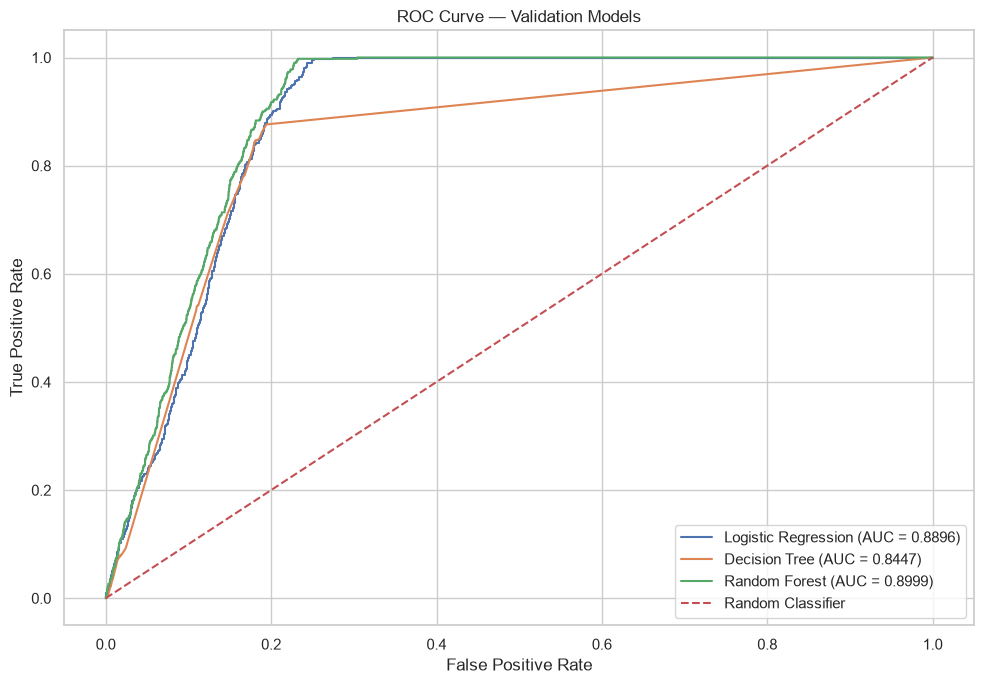

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))

for model_name, probabilities in validation_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_val,
        probabilities
    )

    auc_score = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Validation Models")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Precision-Recall Curve Analysis

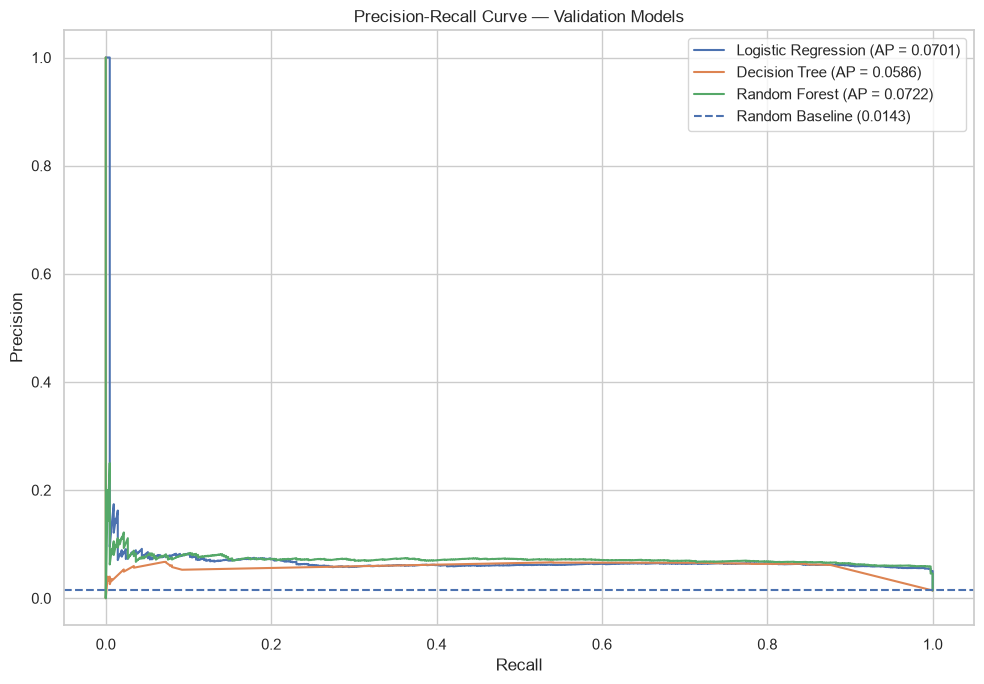

In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for model_name, probabilities in validation_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    ap_score = average_precision_score(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap_score:.4f})"
    )

# Random baseline = positive class prevalence
baseline = y_val.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Random Baseline ({baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Validation Models")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Decision Threshold Analysis

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_test = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50
]

threshold_results = []

for model_name, probabilities in validation_probabilities.items():

    for threshold in thresholds_to_test:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        precision = precision_score(
            y_val,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_val,
            predictions,
            zero_division=0
        )

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1_Score": f1,
            "Predicted_Adopters": predictions.sum()
        })

threshold_results_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_results_df.round(4)
)

,Model,Threshold,Precision,Recall,F1_Score,Predicted_Adopters
0,Logistic Regression,0.05,0.0336,1.0000,0.0651,12248
1,Logistic Regression,0.10,0.0396,1.0000,0.0763,10391
2,Logistic Regression,0.15,0.0442,1.0000,0.0847,9313
3,Logistic Regression,0.20,0.0484,1.0000,0.0924,8506
4,Logistic Regression,0.25,0.0527,0.9976,0.1002,7795
5,Logistic Regression,0.30,0.0559,0.9733,0.1057,7176
6,Logistic Regression,0.35,0.0583,0.9417,0.1099,6651
7,Logistic Regression,0.40,0.0607,0.9005,0.1138,6108
8,Logistic Regression,0.45,0.0621,0.8447,0.1157,5603
9,Logistic Regression,0.50,0.0644,0.8010,0.1192,5124


### Visualize the Precision-Recall-F1 Threshold Trade-off

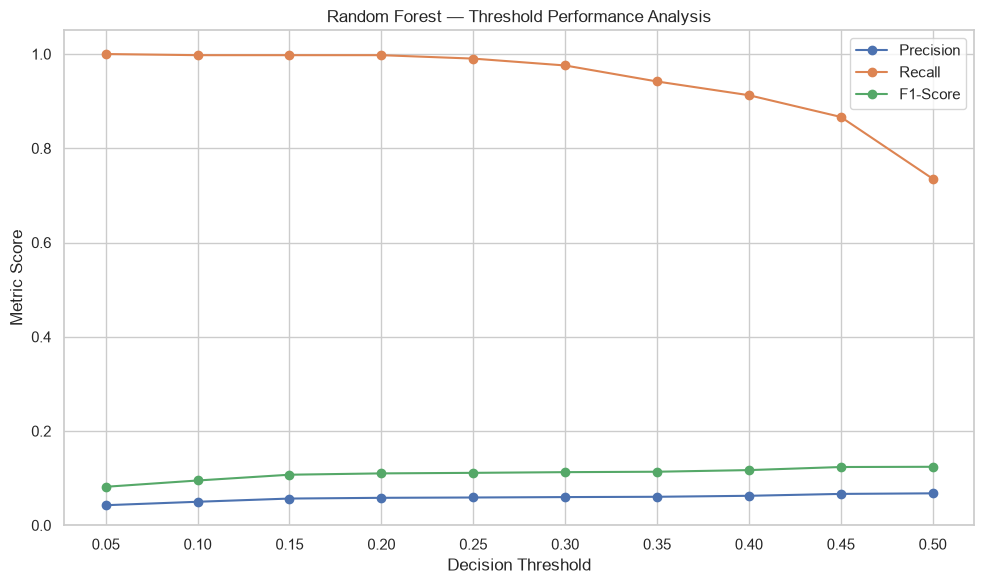

In [12]:
rf_threshold_results = threshold_results_df[
    threshold_results_df["Model"] == "Random Forest"
].copy()

plt.figure(figsize=(10, 6))

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["F1_Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Score")
plt.title("Random Forest — Threshold Performance Analysis")

plt.xticks(thresholds_to_test)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

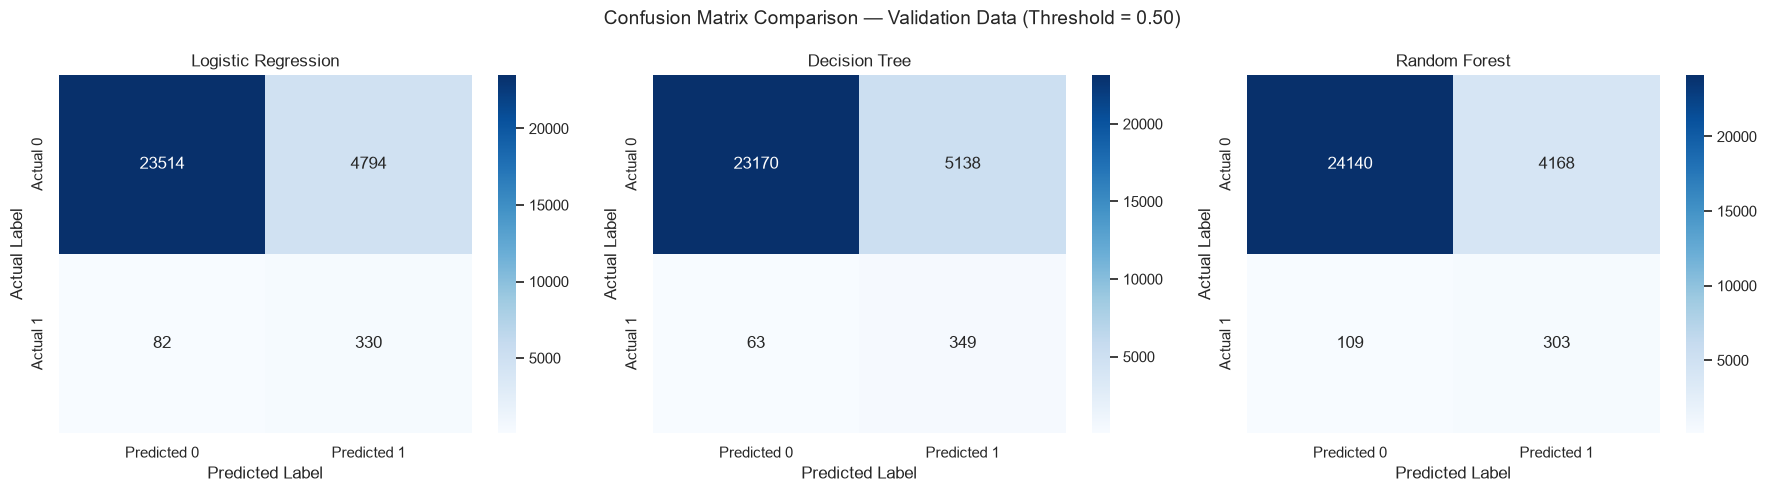

In [13]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, probabilities) in zip(
    axes,
    validation_probabilities.items()
):

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrix Comparison — Validation Data (Threshold = 0.50)",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Calculate Confusion Matrix Metrics

In [14]:
confusion_results = []

for model_name, probabilities in validation_probabilities.items():

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Model": model_name,
        "True_Negatives": tn,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp
    })

confusion_results_df = pd.DataFrame(
    confusion_results
)

display(confusion_results_df)

,Model,True_Negatives,False_Positives,False_Negatives,True_Positives
0,Logistic Regression,23514,4794,82,330
1,Decision Tree,23170,5138,63,349
2,Random Forest,24140,4168,109,303


### Business Cost Analysis

In [15]:
# Illustrative business cost assumptions
FP_COST = 1
FN_COST = 5

business_cost_results = []

for _, row in confusion_results_df.iterrows():

    false_positive_cost = (
        row["False_Positives"] * FP_COST
    )

    false_negative_cost = (
        row["False_Negatives"] * FN_COST
    )

    total_cost = (
        false_positive_cost + false_negative_cost
    )

    business_cost_results.append({
        "Model": row["Model"],
        "False_Positive_Cost": false_positive_cost,
        "False_Negative_Cost": false_negative_cost,
        "Total_Business_Cost": total_cost
    })

business_cost_df = pd.DataFrame(
    business_cost_results
)

business_cost_df = business_cost_df.sort_values(
    by="Total_Business_Cost"
).reset_index(drop=True)

display(business_cost_df)

,Model,False_Positive_Cost,False_Negative_Cost,Total_Business_Cost
0,Random Forest,4168,545,4713
1,Logistic Regression,4794,410,5204
2,Decision Tree,5138,315,5453


### Find the Lowest-Cost Threshold

In [16]:
FP_COST = 1
FN_COST = 5

threshold_cost_results = []

for _, row in threshold_results_df.iterrows():

    model_name = row["Model"]
    threshold = row["Threshold"]

    probabilities = validation_probabilities[model_name]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fp * FP_COST +
        fn * FN_COST
    )

    threshold_cost_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp,
        "Total_Business_Cost": total_cost
    })

threshold_cost_df = pd.DataFrame(
    threshold_cost_results
)

# Sort by lowest business cost
threshold_cost_df = threshold_cost_df.sort_values(
    by="Total_Business_Cost"
).reset_index(drop=True)

print("Top 10 Lowest-Cost Model Configurations")

display(
    threshold_cost_df.head(10)
)

Top 10 Lowest-Cost Model Configurations


,Model,Threshold,False_Positives,False_Negatives,True_Positives,Total_Business_Cost
0,Random Forest,0.50,4168,109,303,4713
1,Logistic Regression,0.50,4794,82,330,5204
2,Random Forest,0.45,5007,55,357,5282
3,Decision Tree,0.50,5138,63,349,5453
4,Decision Tree,0.45,5151,63,349,5466
5,Decision Tree,0.40,5173,63,349,5488
6,Decision Tree,0.35,5255,62,350,5565
7,Decision Tree,0.30,5255,62,350,5565
8,Logistic Regression,0.45,5255,64,348,5575
9,Decision Tree,0.25,5342,57,355,5627


### Visualize Business Cost by Threshold

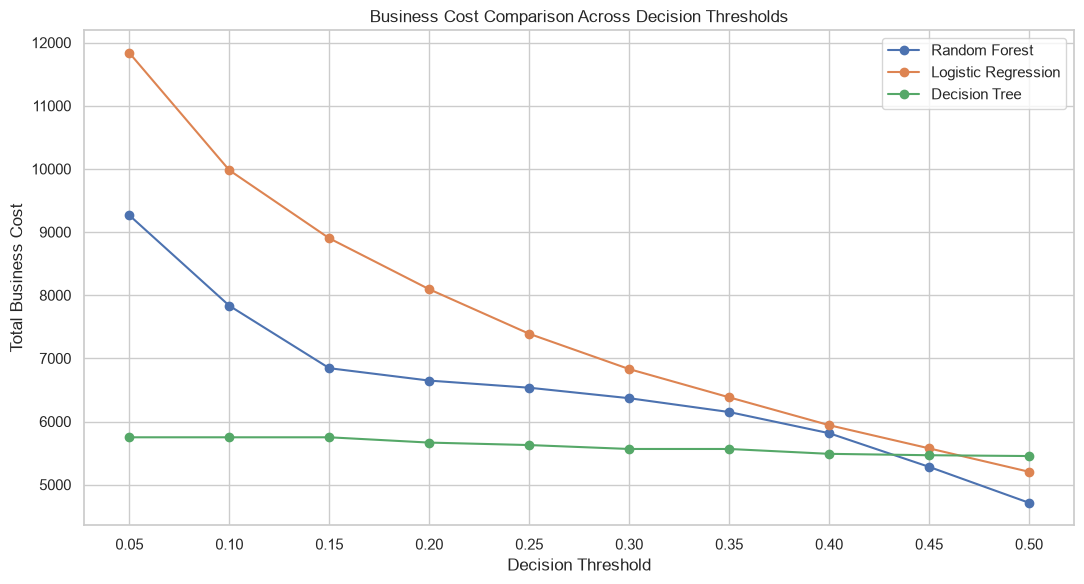

In [17]:
plt.figure(figsize=(11, 6))

for model_name in threshold_cost_df["Model"].unique():

    model_data = threshold_cost_df[
        threshold_cost_df["Model"] == model_name
    ].sort_values("Threshold")

    plt.plot(
        model_data["Threshold"],
        model_data["Total_Business_Cost"],
        marker="o",
        label=model_name
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Total Business Cost")
plt.title("Business Cost Comparison Across Decision Thresholds")
plt.xticks(thresholds_to_test)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Expand the Threshold Search

In [18]:
additional_thresholds = np.arange(0.55, 1.00, 0.05)

extended_results = []

for model_name, probabilities in validation_probabilities.items():

    for threshold in additional_thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        total_cost = fp * FP_COST + fn * FN_COST

        extended_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "False_Positives": fp,
            "False_Negatives": fn,
            "True_Positives": tp,
            "Total_Business_Cost": total_cost
        })

extended_threshold_df = pd.DataFrame(extended_results)

all_threshold_cost_df = pd.concat(
    [threshold_cost_df, extended_threshold_df],
    ignore_index=True
)

all_threshold_cost_df = all_threshold_cost_df.sort_values(
    "Total_Business_Cost"
).reset_index(drop=True)

print("Top 10 Results Across All Tested Thresholds")

display(all_threshold_cost_df.head(10))

Top 10 Results Across All Tested Thresholds


,Model,Threshold,False_Positives,False_Negatives,True_Positives,Total_Business_Cost
0,Random Forest,0.75,8,410,2,2058
1,Decision Tree,0.95,0,412,0,2060
2,Random Forest,0.80,0,412,0,2060
3,Random Forest,0.95,0,412,0,2060
4,Logistic Regression,0.95,0,412,0,2060
5,Random Forest,0.90,0,412,0,2060
6,Random Forest,0.85,0,412,0,2060
7,Decision Tree,0.90,30,411,1,2085
8,Logistic Regression,0.90,110,402,10,2120
9,Decision Tree,0.85,160,403,9,2175


### Add precision, recall, and F1 to the cost comparison

In [19]:
detailed_threshold_results = []

for model_name, probabilities in validation_probabilities.items():

    for threshold in sorted(all_threshold_cost_df["Threshold"].unique()):

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        detailed_threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "False_Positives": fp,
            "False_Negatives": fn,
            "True_Positives": tp,
            "Total_Business_Cost": (
                fp * FP_COST + fn * FN_COST
            )
        })

detailed_threshold_df = pd.DataFrame(detailed_threshold_results)

display(
    detailed_threshold_df.sort_values(
        ["Total_Business_Cost", "Recall"],
        ascending=[True, False]
    ).head(15).round(4)
)

,Model,Threshold,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,Total_Business_Cost
52,Random Forest,0.75,0.2000,0.0049,0.0095,8,410,2,2058
18,Logistic Regression,0.95,0.0000,0.0000,0.0000,0,412,0,2060
37,Decision Tree,0.95,0.0000,0.0000,0.0000,0,412,0,2060
53,Random Forest,0.80,0.0000,0.0000,0.0000,0,412,0,2060
54,Random Forest,0.85,0.0000,0.0000,0.0000,0,412,0,2060
55,Random Forest,0.90,0.0000,0.0000,0.0000,0,412,0,2060
56,Random Forest,0.95,0.0000,0.0000,0.0000,0,412,0,2060
36,Decision Tree,0.90,0.0323,0.0024,0.0045,30,411,1,2085
17,Logistic Regression,0.90,0.0833,0.0243,0.0376,110,402,10,2120
35,Decision Tree,0.85,0.0533,0.0218,0.0310,160,403,9,2175


### Select a practical candidate threshold

In [20]:
rf_threshold_comparison = detailed_threshold_df[
    (detailed_threshold_df["Model"] == "Random Forest") &
    (detailed_threshold_df["Threshold"].between(0.30, 0.70))
].copy()

display(
    rf_threshold_comparison[
        [
            "Threshold",
            "Precision",
            "Recall",
            "F1",
            "False_Positives",
            "False_Negatives",
            "True_Positives",
            "Total_Business_Cost"
        ]
    ].sort_values("Threshold").round(4)
)

,Threshold,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,Total_Business_Cost
43,0.30,0.0598,0.9757,0.1127,6319,10,402,6369
44,0.35,0.0605,0.9417,0.1136,6030,24,388,6150
45,0.40,0.0626,0.9126,0.1171,5635,36,376,5815
46,0.45,0.0666,0.8665,0.1236,5007,55,357,5282
47,0.50,0.0678,0.7354,0.1241,4168,109,303,4713
48,0.55,0.0713,0.5874,0.1272,3151,170,242,4001
49,0.60,0.0703,0.3811,0.1187,2077,255,157,3352
50,0.65,0.0715,0.2112,0.1068,1130,325,87,2755
51,0.70,0.0735,0.0607,0.0665,315,387,25,2250


### Select the provisional threshold

In [21]:
selected_model_name = "Random Forest"
selected_threshold = 0.55

selected_result = detailed_threshold_df[
    (detailed_threshold_df["Model"] == selected_model_name) &
    (detailed_threshold_df["Threshold"] == selected_threshold)
]

display(selected_result.round(4))

,Model,Threshold,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,Total_Business_Cost
48,Random Forest,0.55,0.0713,0.5874,0.1272,3151,170,242,4001


### Save the selected threshold and validation results

In [22]:
import json

selected_model_info = {
    "project": "AI-Powered Feature Adoption Prediction & Causal Impact Analysis",
    "selected_model": selected_model_name,
    "decision_threshold": selected_threshold,
    "selection_metric": "F1-score",
    "validation_precision": 0.0713,
    "validation_recall": 0.5874,
    "validation_f1": 0.1272,
    "validation_true_positives": 242,
    "validation_false_positives": 3151,
    "validation_false_negatives": 170,
    "validation_business_cost": 4001
}

output_dir = Path("../models/evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "selected_model_info.json", "w") as file:
    json.dump(selected_model_info, file, indent=4)

detailed_threshold_df.to_csv(
    output_dir / "threshold_analysis_results.csv",
    index=False
)

print("Selected model information saved successfully.")
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)

Selected model information saved successfully.
Selected model: Random Forest
Selected threshold: 0.55


### Load the final Random Forest model

In [23]:
model_files = list(
    Path("../models/baseline").rglob("random_forest.joblib")
)

if not model_files:
    raise FileNotFoundError("random_forest.joblib was not found.")

final_model_path = model_files[0]

print("Model path:", final_model_path)

Model path: ..\models\baseline\random_forest.joblib


### Load and verify the model

In [24]:
final_model = joblib.load(final_model_path)

print("Final Random Forest model loaded successfully.")
print("Model type:", type(final_model).__name__)
print("Pipeline steps:")

for step_name, step_object in final_model.named_steps.items():
    print(f"{step_name}: {type(step_object).__name__}")

Final Random Forest model loaded successfully.
Model type: Pipeline
Pipeline steps:
preprocessor: ColumnTransformer
classifier: RandomForestClassifier


### Retrain Random Forest on the full training dataset

In [25]:
final_model.fit(X_train, y_train)

print("Final Random Forest model trained successfully.")
print("Training observations:", len(X_train))
print("Training positive cases:", int(y_train.sum()))
print("Training positive rate:", round(y_train.mean() * 100, 2), "%")

Final Random Forest model trained successfully.
Training observations: 70577
Training positive cases: 1620
Training positive rate: 2.3 %


### Generate test-set probabilities

In [26]:
# Predict adoption probabilities
y_test_probabilities = final_model.predict_proba(X_test)[:, 1]

print("Test probabilities generated successfully.")
print("Number of predictions:", len(y_test_probabilities))
print("Minimum probability:", round(y_test_probabilities.min(), 4))
print("Maximum probability:", round(y_test_probabilities.max(), 4))
print("Mean probability:", round(y_test_probabilities.mean(), 4))

Test probabilities generated successfully.
Number of predictions: 56642
Minimum probability: 0.0
Maximum probability: 0.79
Mean probability: 0.072


### Convert probabilities into binary predictions

In [27]:
# Apply selected decision threshold
y_test_pred = (
    y_test_probabilities >= selected_threshold
).astype(int)

print("Test predictions generated successfully.")
print("Predicted adopters:", int(y_test_pred.sum()))
print("Predicted non-adopters:", int((y_test_pred == 0).sum()))
print(
    "Predicted adoption rate:",
    round(y_test_pred.mean() * 100, 2),
    "%"
)

Test predictions generated successfully.
Predicted adopters: 3487
Predicted non-adopters: 53155
Predicted adoption rate: 6.16 %


### Evaluate final test-set classification metrics

In [30]:
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test, y_test_probabilities
    ),
    "Average_Precision": average_precision_score(
        y_test, y_test_probabilities
    )
}

test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=["Random Forest"]
)

display(test_metrics_df.round(4))

,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
Random Forest,0.9403,0.0688,0.6434,0.1244,0.9547,0.0722


### Generate the final confusion matrix

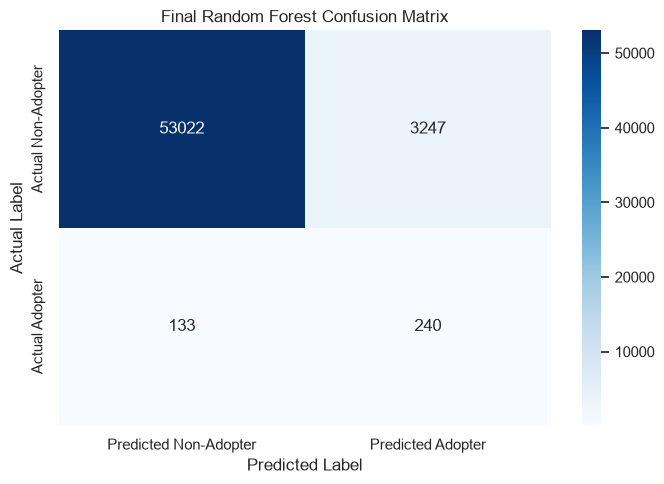

Confusion Matrix:
[[53022  3247]
 [  133   240]]


In [31]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Non-Adopter", "Predicted Adopter"],
    yticklabels=["Actual Non-Adopter", "Actual Adopter"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

### Calculate final business-oriented metrics

In [32]:
tn, fp, fn, tp = cm.ravel()

total_users = len(y_test)

actual_adopters = tp + fn
predicted_adopters = tp + fp

final_business_metrics = {
    "Total_Test_Users": total_users,
    "Actual_Adopters": actual_adopters,
    "Predicted_Adopters": predicted_adopters,
    "Adopters_Correctly_Identified": tp,
    "Adoption_Rate": actual_adopters / total_users,
    "Precision": tp / predicted_adopters if predicted_adopters else 0,
    "Recall": tp / actual_adopters if actual_adopters else 0,
    "False_Discovery_Rate": fp / predicted_adopters if predicted_adopters else 0,
    "Missed_Adopter_Rate": fn / actual_adopters if actual_adopters else 0
}

final_business_metrics_df = pd.DataFrame(
    [final_business_metrics]
)

display(final_business_metrics_df.round(4))

,Total_Test_Users,Actual_Adopters,Predicted_Adopters,Adopters_Correctly_Identified,Adoption_Rate,Precision,Recall,False_Discovery_Rate,Missed_Adopter_Rate
0,56642,373,3487,240,0.0066,0.0688,0.6434,0.9312,0.3566


### Compare validation and test performance

In [33]:
validation_comparison = {
    "Dataset": ["Validation", "Test"],
    "Precision": [
        0.0713,
        precision_score(y_test, y_test_pred, zero_division=0)
    ],
    "Recall": [
        0.5874,
        recall_score(y_test, y_test_pred, zero_division=0)
    ],
    "F1_Score": [
        0.1272,
        f1_score(y_test, y_test_pred, zero_division=0)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, validation_probabilities["Random Forest"]),
        roc_auc_score(y_test, y_test_probabilities)
    ],
    "Average_Precision": [
        average_precision_score(y_val, validation_probabilities["Random Forest"]),
        average_precision_score(y_test, y_test_probabilities)
    ]
}

validation_test_comparison_df = pd.DataFrame(validation_comparison)

display(validation_test_comparison_df.round(4))

,Dataset,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
0,Validation,0.0713,0.5874,0.1272,0.8999,0.0722
1,Test,0.0688,0.6434,0.1244,0.9547,0.0722


### Visualize validation vs. test performance

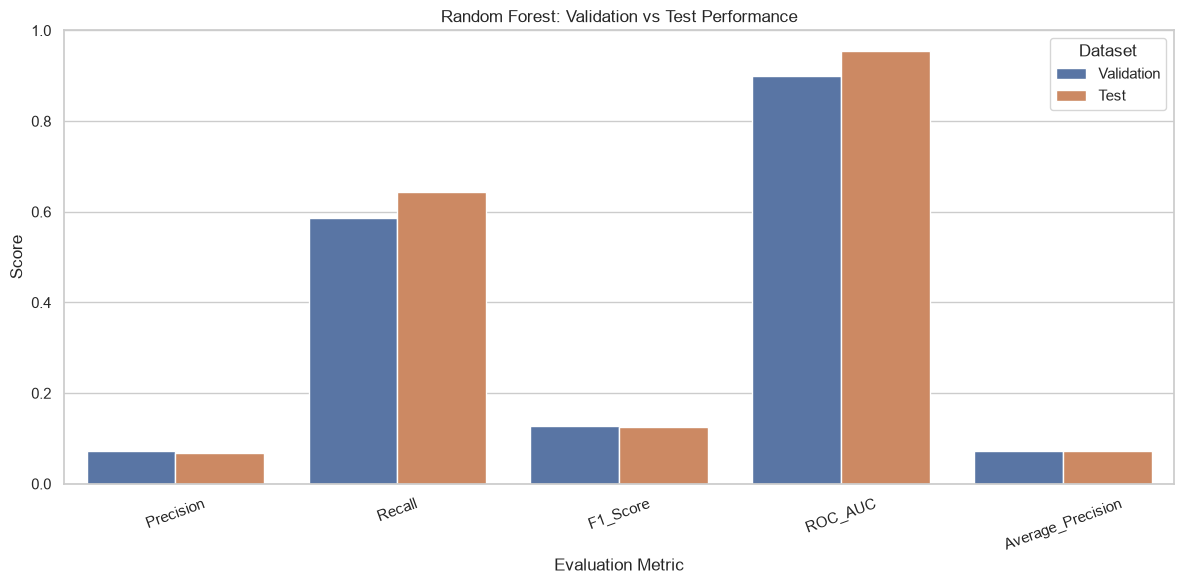

In [34]:
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC",
    "Average_Precision"
]

comparison_plot_df = validation_test_comparison_df.melt(
    id_vars="Dataset",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot_df,
    x="Metric",
    y="Score",
    hue="Dataset"
)

plt.title("Random Forest: Validation vs Test Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

### Save the final model

In [35]:
# Create final model directory
final_model_dir = Path("../models/final")
final_model_dir.mkdir(parents=True, exist_ok=True)

# Save final model
final_model_path = final_model_dir / "random_forest_final.joblib"

joblib.dump(final_model, final_model_path)

print("Final model saved successfully.")
print("Saved location:", final_model_path)

Final model saved successfully.
Saved location: ..\models\final\random_forest_final.joblib


### Save test predictions

In [36]:
test_predictions_df = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": y_test_pred,
    "adoption_probability": y_test_probabilities,
    "decision_threshold": selected_threshold
})

predictions_path = Path("../data/processed/final_test_predictions.csv")
predictions_path.parent.mkdir(parents=True, exist_ok=True)

test_predictions_df.to_csv(predictions_path, index=False)

print("Test predictions saved successfully.")
print("Shape:", test_predictions_df.shape)
print("Saved location:", predictions_path)

Test predictions saved successfully.
Shape: (56642, 4)
Saved location: ..\data\processed\final_test_predictions.csv


### Save final evaluation metrics

In [37]:
final_evaluation_path = (
    Path("../models/evaluation") /
    "final_test_evaluation.csv"
)

final_evaluation_path.parent.mkdir(parents=True, exist_ok=True)

test_metrics_df.to_csv(final_evaluation_path, index=True)

print("Final evaluation metrics saved successfully.")
print("Saved location:", final_evaluation_path)

Final evaluation metrics saved successfully.
Saved location: ..\models\evaluation\final_test_evaluation.csv


### Save confusion matrix

In [38]:
confusion_matrix_df = pd.DataFrame(
    cm,
    index=["Actual_Non_Adopter", "Actual_Adopter"],
    columns=["Predicted_Non_Adopter", "Predicted_Adopter"]
)

confusion_matrix_path = (
    Path("../models/evaluation") /
    "final_confusion_matrix.csv"
)

confusion_matrix_df.to_csv(confusion_matrix_path)

print("Confusion matrix saved successfully.")

Confusion matrix saved successfully.


### Verify saved artifacts

In [39]:
artifacts_to_check = [
    final_model_path,
    predictions_path,
    final_evaluation_path,
    confusion_matrix_path,
    Path("../models/evaluation/selected_model_info.json"),
    Path("../models/evaluation/threshold_analysis_results.csv")
]

for artifact in artifacts_to_check:
    print(
        f"{'EXISTS' if artifact.exists() else 'MISSING'}: {artifact}"
    )

EXISTS: ..\models\final\random_forest_final.joblib
EXISTS: ..\data\processed\final_test_predictions.csv
EXISTS: ..\models\evaluation\final_test_evaluation.csv
EXISTS: ..\models\evaluation\final_confusion_matrix.csv
EXISTS: ..\models\evaluation\selected_model_info.json
EXISTS: ..\models\evaluation\threshold_analysis_results.csv


### Extract Random Forest feature importance